In [40]:
# Import required libraries
import sys
#sys.path.append(stm_graph_path)
#import stm_graph
import os
import pandas as pd
import numpy as np
import datetime
from datetime import timedelta
import matplotlib.pyplot as plt
import contextily as ctx
!pip install pyarrow
import pyarrow

# Define the data and output directories
DATA_DIR = ""
CAMERA_DATASET = "yearly_red_light_cameras.csv"
REDLIGHT_DATASET = "all_red_light_tickets_geocoded.parquet"
CRASH_DATASET = "Motor_Vehicle_Collisions_from2016.csv"


OUTPUT_DIR = ""

In [41]:
# Step 1: Read the raw data
print(f"Reading camera data from {CAMERA_DATASET}")
camera_df = pd.read_csv(CAMERA_DATASET, low_memory=False)

print(f"Reading raw crash incident data from {CRASH_DATASET}")
crash_df = pd.read_csv(CRASH_DATASET, low_memory=False)

print(f"Reading raw RED LIGHT with LATITUDE/LONGITUDE incident data from {REDLIGHT_DATASET}")
redlight_df = pd.read_parquet(REDLIGHT_DATASET, engine='pyarrow')
base_redlight_df = redlight_df.copy()

Reading camera data from yearly_red_light_cameras.csv
Reading raw crash incident data from Motor_Vehicle_Collisions_from2016.csv
Reading raw RED LIGHT with LATITUDE/LONGITUDE incident data from all_red_light_tickets_geocoded.parquet


In [42]:
#camera_df.head(10)
print("\nColumn names:")
print(crash_df.columns.tolist())
#crash_df.head(10)

#crash_df['Violation Time'] = crash_df['Violation Time'].astype(int)




Column names:
['CRASH DATE', 'CRASH TIME', 'BOROUGH', 'ZIP CODE', 'LATITUDE', 'LONGITUDE', 'LOCATION', 'ON STREET NAME', 'CROSS STREET NAME', 'OFF STREET NAME', 'NUMBER OF PERSONS INJURED', 'NUMBER OF PERSONS KILLED', 'NUMBER OF PEDESTRIANS INJURED', 'NUMBER OF PEDESTRIANS KILLED', 'NUMBER OF CYCLIST INJURED', 'NUMBER OF CYCLIST KILLED', 'NUMBER OF MOTORIST INJURED', 'NUMBER OF MOTORIST KILLED', 'CONTRIBUTING FACTOR VEHICLE 1', 'CONTRIBUTING FACTOR VEHICLE 2', 'CONTRIBUTING FACTOR VEHICLE 3', 'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5', 'COLLISION_ID', 'VEHICLE TYPE CODE 1', 'VEHICLE TYPE CODE 2', 'VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4', 'VEHICLE TYPE CODE 5']


In [43]:
camera_loc_raw = []
for r in camera_df.itertuples(index=False):
    camera_loc_raw.append((r.Latitude, r.Longitude))
camera_location_pairs = list(dict.fromkeys(camera_loc_raw))
print(camera_location_pairs)

#only get indices which match
mask = pd.MultiIndex.from_frame(redlight_df[['Latitude', 'Longitude']]).isin(camera_location_pairs)
df_filtered = redlight_df[mask]
#basically pointless lol

df_first_only = df_filtered.sort_values(df_filtered.columns.tolist())\
          .drop_duplicates(subset=['Latitude','Longitude'], keep='first')


print(f"Dataset shape: {redlight_df.shape}")
print(f"Dataset shape: {df_first_only.shape}")
#df_first_only.head(10)


[(40.76534581872, -73.744281359829), (40.836315979639, -73.869993981845), (40.575848003186, -74.119818030912), (40.680840979647, -73.975119979109), (40.883026984931, -73.853247023119), (40.646636989269, -73.924767958897), (40.655629011176, -74.006574998613), (40.820244979495, -73.890711029009), (40.769429314309, -73.910277827601), (40.868486017393, -73.842415005827), (40.736805019312, -73.877641965578), (40.658685011165, -73.890809013457), (40.73857460671, -73.887233461201), (40.67679801056, -73.843870020399), (40.666101989646, -73.828068959447), (40.610265103453, -74.097428123512), (40.735626817092, -73.923064923809), (40.609514001109, -73.75371896371), (40.613023001055, -74.158826989196), (40.607758998223, -74.132040019209), (40.698062018816, -73.962818781828), (40.770378020019, -73.917697991206), (40.862134211167, -73.929992566784), (40.607247995495, -73.96733402925), (40.58993400102, -73.804583034387), (40.67435158448, -73.801216862072), (40.869579981486, -73.826266012074), (40.675

In [44]:
first_issue_date_dict = {}


#create a key-value dictionary for lat/longitude to match to date
for i in df_first_only.index:

    key = (df_first_only.at[i, 'Latitude'] ,df_first_only.at[i, 'Longitude']) #Rename columns accordingly
    value = (df_first_only.at[i, 'issue_date']) #Rename columns accordingly

    dictionary = {key: value}
    first_issue_date_dict.update(dictionary)

print(first_issue_date_dict)

{(40.724543778182, -73.932211669766): Timestamp('2017-12-31 00:00:00'), (40.706412916493, -74.017835944051): Timestamp('2018-01-17 00:00:00'), (40.783851, -73.929187): Timestamp('2025-08-02 00:00:00'), (40.811211228169, -73.836368188364): Timestamp('2025-07-03 00:00:00'), (40.669381493083, -73.920077781156): Timestamp('2016-05-27 00:00:00'), (40.678547984305, -73.949685010104): Timestamp('2016-05-29 00:00:00'), (40.616169986602, -73.944866002512): Timestamp('2016-05-29 00:00:00'), (40.76534581872, -73.744281359829): Timestamp('2016-05-29 00:00:00'), (40.678792987335, -73.953013966769): Timestamp('2016-05-29 00:00:00'), (40.736826015979, -73.931603987669): Timestamp('2016-05-29 00:00:00'), (40.610265103453, -74.097428123512): Timestamp('2016-05-29 00:00:00'), (40.676349201555, -74.001009833999): Timestamp('2016-05-29 00:00:00'), (40.856708186146, -73.86938579095): Timestamp('2016-05-29 00:00:00'), (40.676272004226, -73.910936980467): Timestamp('2016-05-29 00:00:00'), (40.678094020429, -

(array([128869., 131109.,  98617., 123431., 157458., 141275., 104420.,
        121892., 146779., 125371.,  95556., 117863., 137259.,  92343.,
         76965.,  72960., 132882., 110305.,  89461., 150606., 179511.,
        153278., 120358., 179685., 183064., 157841., 147033., 250342.,
        346246., 168476., 144857., 198888., 195094., 169125., 143519.,
        173771., 180142., 114063., 267877., 491807.]),
 array([16942.  , 17034.95, 17127.9 , 17220.85, 17313.8 , 17406.75,
        17499.7 , 17592.65, 17685.6 , 17778.55, 17871.5 , 17964.45,
        18057.4 , 18150.35, 18243.3 , 18336.25, 18429.2 , 18522.15,
        18615.1 , 18708.05, 18801.  , 18893.95, 18986.9 , 19079.85,
        19172.8 , 19265.75, 19358.7 , 19451.65, 19544.6 , 19637.55,
        19730.5 , 19823.45, 19916.4 , 20009.35, 20102.3 , 20195.25,
        20288.2 , 20381.15, 20474.1 , 20567.05, 20660.  ]),
 <BarContainer object of 40 artists>)

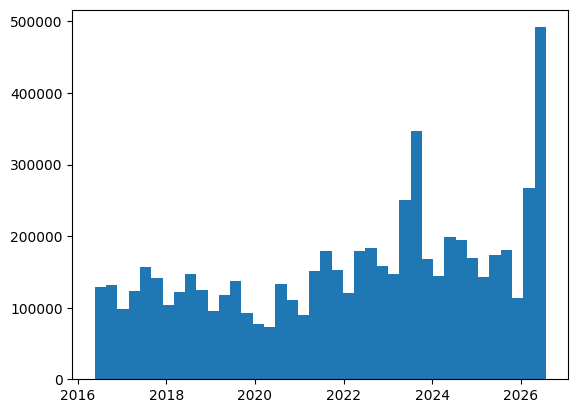

In [ ]:
df_overall = redlight_df.copy()





In [45]:
keys = pd.Series(
    list(zip(redlight_df['Latitude'], redlight_df['Longitude'])),
    index=redlight_df.index
)

issue_dates = pd.to_datetime(redlight_df['issue_date'])
first_dates = pd.to_datetime(keys.map(first_issue_date_dict))
redlight_df['days_since_install'] = issue_dates - first_dates
#converts it to an integer value
redlight_df['days_since_install'] = redlight_df['days_since_install'].dt.days


redlight_df.head(10)


,summons_number,issue_date,violation_time,violation_code,street_name,intersecting_street,violation_county,plate_id,registration_state,search_query,Latitude,Longitude,days_since_install
0,5092469481,2016-07-10,0143A,7,ALLERTON AVE (W/B) @,BARNES AVE,BX,GZH7067,NY,"ALLERTON AVE AND BARNES AVE, NEW YORK, NY",40.865510,-73.863525,42
1,5092451658,2016-07-08,0400P,7,ALLERTON AVE (W/B) @,BARNES AVE,BX,GZH7067,NY,"ALLERTON AVE AND BARNES AVE, NEW YORK, NY",40.865510,-73.863525,40
2,5093429077,2016-09-09,0102P,7,NORTHERN BLVD (E/B),@ MARATHON PKWY,QN,HHF9280,NY,"NORTHERN BLVD AND MARATHON PKWY, NEW YORK, NY",40.768397,-73.737528,103
3,5094755523,2016-12-18,0442P,7,NARROWS RD (W/B) @ C,LOVE RD,ST,W98HFL,NJ,"NARROWS RD AND C LOVE RD, NEW YORK, NY",40.610956,-74.098098,201
4,5093457784,2016-09-12,1146A,7,ATLANTIC AVE (W/B) @,KINGSTON AVE,BK,DTZ584,SC,"ATLANTIC AVE AND KINGSTON AVE, NEW YORK, NY",40.678094,-73.941372,106
5,5093709906,2016-09-30,0337P,7,CONEY ISLAND AVE (S/,B) @ DORCHESTER RD,BK,HDV1961,NY,"CONEY ISLAND AVE AND DORCHESTER RD, NEW YORK, NY",40.637289,-73.968221,124
6,5094348279,2016-11-25,0145P,7,REMSEN AVE (N/B) @ L,ENOX RD,BK,GMW1054,NY,"REMSEN AVE AND L ENOX RD, NEW YORK, NY",40.655854,-73.923375,181
7,5095118440,2017-01-24,0355P,7,CLASSON AVE (N/B) @,FLUSHING AVE,BK,GTC1972,NY,"CLASSON AVE AND FLUSHING AVE, NEW YORK, NY",40.698207,-73.961894,238
8,5095252200,2017-02-07,0130A,7,WILLIAMSBURG ST (S/B,) @ FLUSHING AVE,BK,HJJ4891,NY,"WILLIAMSBURG ST AND FLUSHING AVE, NEW YORK, NY",40.698062,-73.962819,254
9,5095654465,2017-03-16,0957P,7,CONEY ISLAND AVE (S/,B) @ DORCHESTER RD,BK,HNJ4580,NY,"CONEY ISLAND AVE AND DORCHESTER RD, NEW YORK, NY",40.637289,-73.968221,291


(array([321939., 417968., 173595., 180768., 168838., 149000., 117884.,
        133277., 149647., 129093., 105903., 125969., 135270.,  94648.,
         84004.,  88517., 133728., 109219., 100648., 160008., 178693.,
        147103., 131120., 172565., 162764., 150113., 160864., 256796.,
        293428., 155010., 148472., 186500., 180781., 155189., 139003.,
        163591., 145057., 104341., 100926., 108159.]),
 array([  -6. ,   87.1,  180.2,  273.3,  366.4,  459.5,  552.6,  645.7,
         738.8,  831.9,  925. , 1018.1, 1111.2, 1204.3, 1297.4, 1390.5,
        1483.6, 1576.7, 1669.8, 1762.9, 1856. , 1949.1, 2042.2, 2135.3,
        2228.4, 2321.5, 2414.6, 2507.7, 2600.8, 2693.9, 2787. , 2880.1,
        2973.2, 3066.3, 3159.4, 3252.5, 3345.6, 3438.7, 3531.8, 3624.9,
        3718. ]),
 <BarContainer object of 40 artists>)

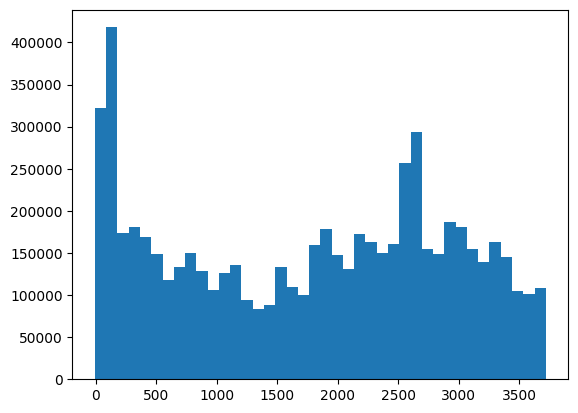

In [46]:
#redlight_df['issue_date'].value_counts().sort_index().plot.bar()

!pip install matplotlib
import matplotlib
import matplotlib.pyplot as plt

matplotlib.pyplot.hist(redlight_df['days_since_install'], bins=40, color=None, edgecolor=None, label=None, density=False)



In [60]:
import pandas as pd
import matplotlib.pyplot as plt

# Work on a copy
df = redlight_df.copy()

# Ensure numeric values and normalize coordinates
df["days_since_install"] = pd.to_numeric(df["days_since_install"], errors="coerce")
df["Latitude"] = pd.to_numeric(df["Latitude"], errors="coerce").round(6)
df["Longitude"] = pd.to_numeric(df["Longitude"], errors="coerce").round(6)

# Preserve original row order and absolute day values
df["_original_order"] = range(len(df))

# Sort by camera location and absolute day
df = df.sort_values(
    ["Latitude", "Longitude", "days_since_install"]
).copy()

# Find the previous observation day for each location
df["previous_day"] = df.groupby(
    ["Latitude", "Longitude"]
)["days_since_install"].shift(1)

# Number of completely missing days between observations
df["gap_days"] = (
    df["days_since_install"] - df["previous_day"] - 1
)

# Start a new installation period if at least 14 days are missing
df["new_period"] = (df["gap_days"] >= 14).fillna(False)

# Assign a separate period number to each location
df["period"] = (
    df.groupby(["Latitude", "Longitude"])["new_period"].cumsum() + 1
)

# Get the first absolute day of each installation period
df["installation_day"] = df.groupby(
    ["Latitude", "Longitude", "period"]
)["days_since_install"].transform("min")

# Get the LAST absolute day of each installation period
df["deinstallation_day"] = df.groupby(
    ["Latitude", "Longitude", "period"]
)["days_since_install"].transform("max")


#drop all periods that are less than one YEAR
rows_to_drop = df[df["deinstallation_day"] - df["installation_day"] < 10*365].index
df.drop(rows_to_drop, inplace=True)

# Relative offset: days since the start of each installation period
df["days_since_install"] = (
    df["days_since_install"] - df["installation_day"]
)

#Drop all rows that are more than one year above their period
rows_to_drop = df[df["days_since_install"] > 10*365].index
df.drop(rows_to_drop, inplace=True)




# Restore original row order
df = df.sort_values("_original_order")

# Remove temporary columns, keeping period and absolute day

df = df.drop(columns=[
    "_original_order",
    "previous_day",
    "gap_days",
    "new_period",
    "installation_day",
])

print("Reset relative issue_date offsets for new installation periods.")
print(df[[
    "Latitude",
    "Longitude",
    "days_since_install",
    "period",
    "issue_date"
]].head(20))

Reset relative issue_date offsets for new installation periods.
     Latitude  Longitude  days_since_install  period issue_date
12  40.589934 -73.804583                 375       1 2017-06-06
14  40.749125 -73.729170                 172       1 2016-11-17
17  40.736805 -73.877642                 183       1 2016-11-27
19  40.561076 -74.169832                  35       1 2016-07-03
20  40.738575 -73.887233                 107       1 2016-09-13
28  40.743872 -73.926193                 339       1 2017-05-04
34  40.589934 -73.804583                 382       1 2017-06-13
35  40.743872 -73.926193                  74       1 2016-08-12
36  40.589934 -73.804583                 168       1 2016-11-11
47  40.749125 -73.729170                 328       1 2017-04-22
48  40.827678 -73.922074                  99       1 2016-09-05
50  40.738575 -73.887233                 328       1 2017-04-22
54  40.739906 -73.894215                 379       1 2017-06-12
59  40.749125 -73.729170                

(array([41606., 39314., 26568., 36544., 48918., 41201., 28584., 33762.,
        41615., 35140., 24770., 30917., 42878., 31305., 20722., 19322.,
        35637., 31156., 22936., 38946., 48157., 41581., 28395., 41199.,
        47988., 39351., 32209., 43798., 91846., 46343., 31423., 45033.,
        51147., 43542., 31782., 39124., 44867., 30577., 23687., 25283.]),
 array([16946.   , 17037.675, 17129.35 , 17221.025, 17312.7  , 17404.375,
        17496.05 , 17587.725, 17679.4  , 17771.075, 17862.75 , 17954.425,
        18046.1  , 18137.775, 18229.45 , 18321.125, 18412.8  , 18504.475,
        18596.15 , 18687.825, 18779.5  , 18871.175, 18962.85 , 19054.525,
        19146.2  , 19237.875, 19329.55 , 19421.225, 19512.9  , 19604.575,
        19696.25 , 19787.925, 19879.6  , 19971.275, 20062.95 , 20154.625,
        20246.3  , 20337.975, 20429.65 , 20521.325, 20613.   ]),
 <BarContainer object of 40 artists>)

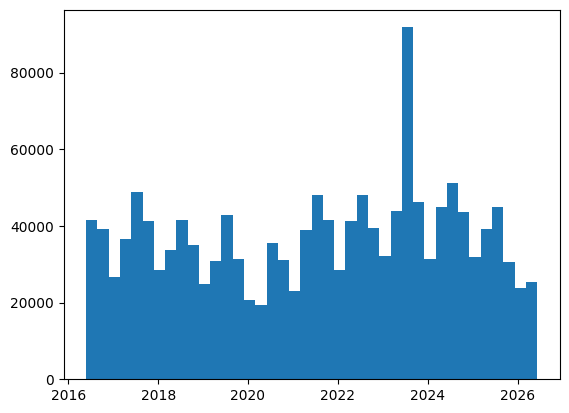

In [61]:
#matplotlib.pyplot.hist(df['days_since_install'], bins=40, color=None, edgecolor=None, label=None, density=False)

matplotlib.pyplot.hist(df['issue_date'], bins=40, color=None, edgecolor=None, label=None, density=False)



In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
!pip install seaborn
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose

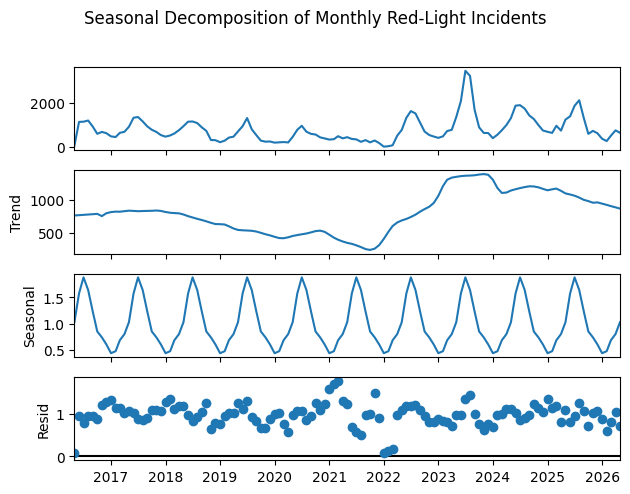

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Start with your processed dataframe
ts_df = df.copy()

# Ensure issue_date is datetime
ts_df["issue_date"] = pd.to_datetime(
    ts_df["issue_date"], errors="coerce"
)

# Select one camera location and installation period
latitude = ts_df["Latitude"].iloc[0]
longitude = ts_df["Longitude"].iloc[0]
period = ts_df["period"].iloc[0]

camera_df = ts_df[
    (ts_df["Latitude"] == latitude) &
    (ts_df["Longitude"] == longitude) &
    (ts_df["period"] == period)
].copy()

# Aggregate incidents by month
monthly_counts = (
    camera_df
    .set_index("issue_date")
    .resample("MS")
    .size()
)

# Fill months without recorded incidents with zero
monthly_counts = monthly_counts.asfreq("MS", fill_value=0)

# Multiplicative decomposition requires strictly positive values
# Use additive decomposition if any months have zero incidents
if (monthly_counts <= 0).any():
    result = seasonal_decompose(
        monthly_counts,
        model="additive",
        period=12,
        extrapolate_trend="freq"
    )
else:
    result = seasonal_decompose(
        monthly_counts,
        model="multiplicative",
        period=12,
        extrapolate_trend="freq"
    )

result.plot()
plt.suptitle(
    "Seasonal Decomposition of Monthly Red-Light Incidents",
    y=1.02
)
plt.tight_layout()
plt.show()

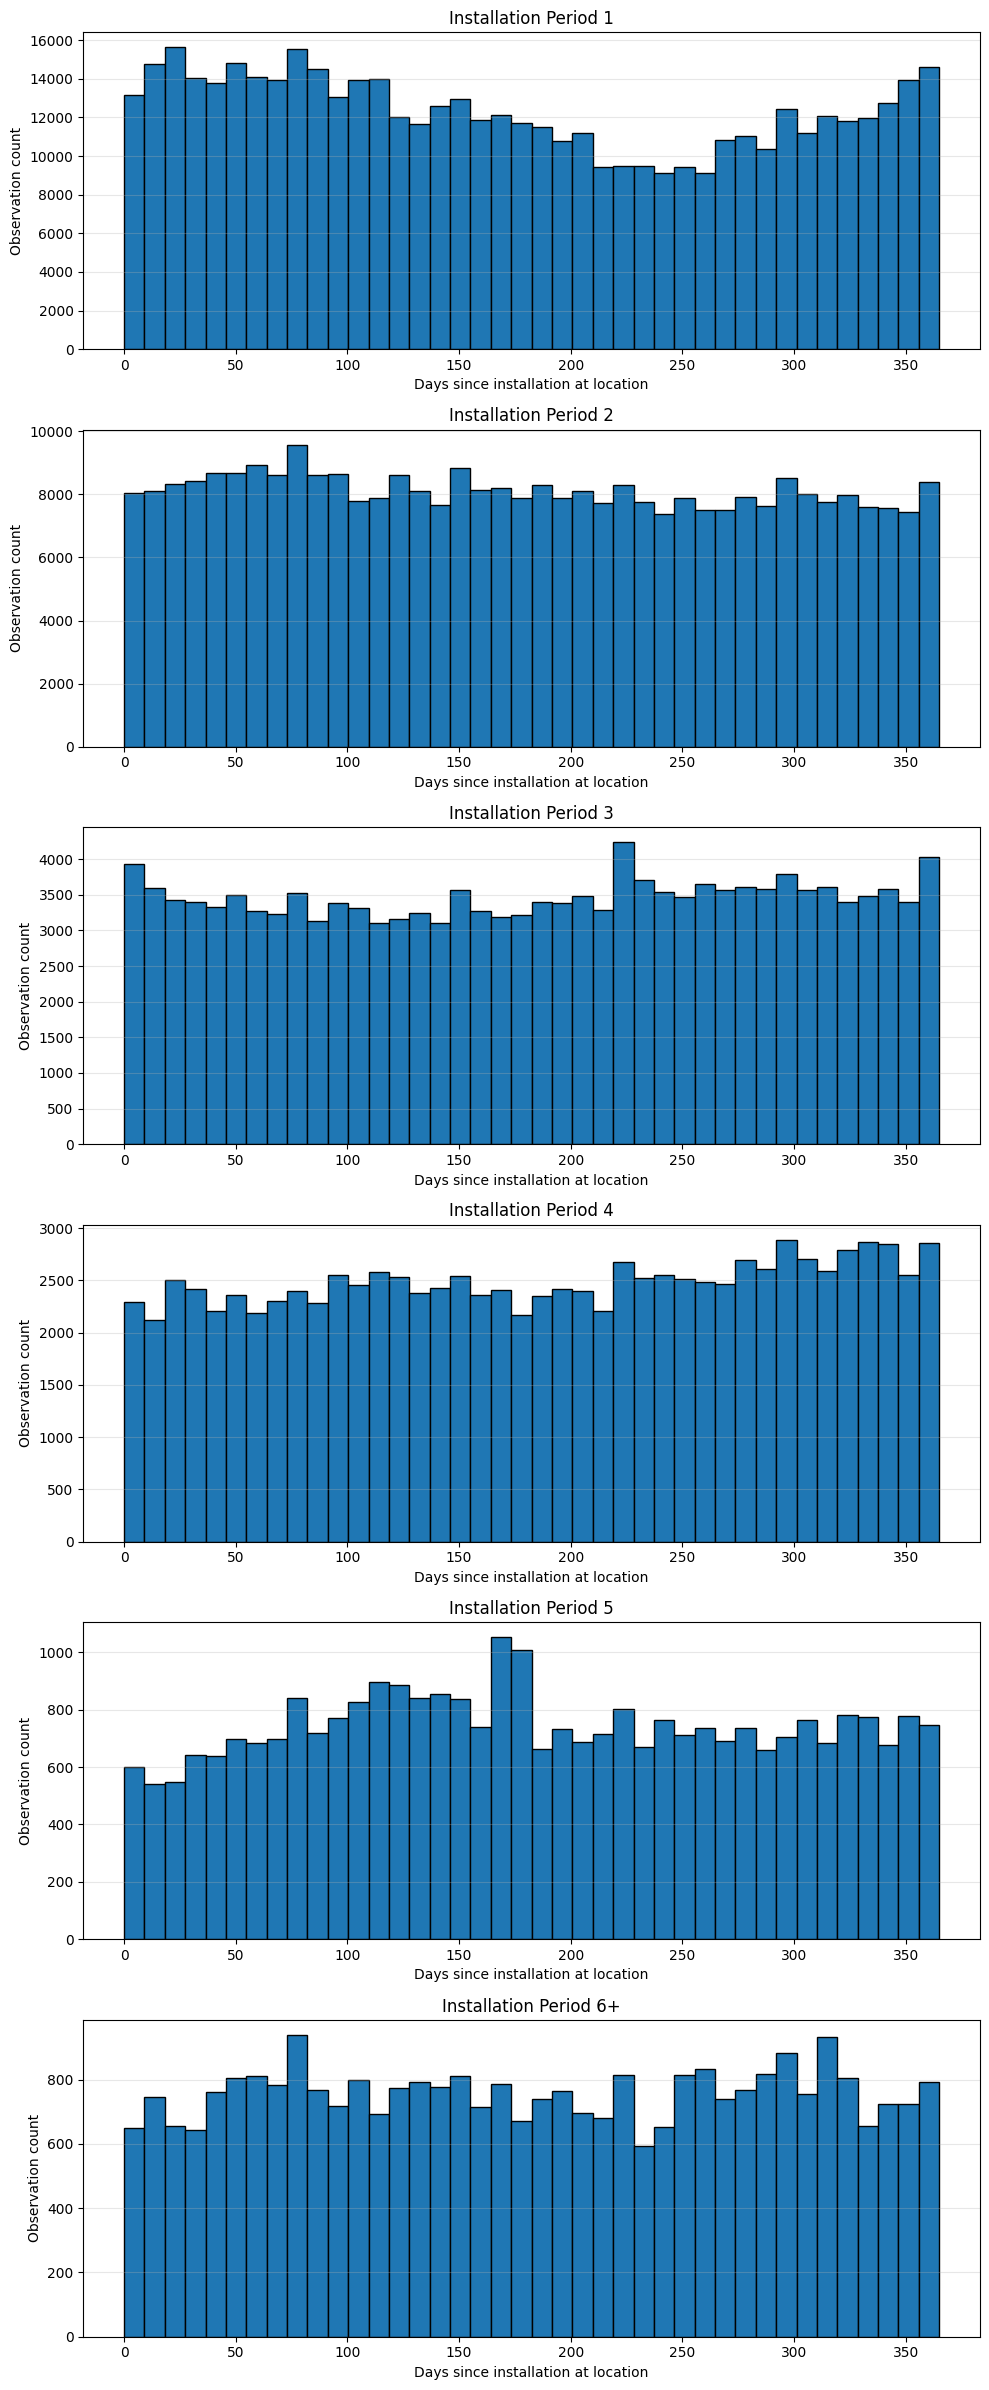

In [ ]:
# Merge all periods 6 and above into one group
df["period_group"] = df["period"].apply(
    lambda p: "6+" if p >= 6 else str(p)
)

periods = ["1", "2", "3", "4", "5", "6+"]

fig, axes = plt.subplots(
    len(periods), 1,
    figsize=(10, 4 * len(periods)),
    sharex=False,
    squeeze=False
)

for period, ax in zip(periods, axes.flatten()):
    values = df.loc[
        df["period_group"] == period, "issue_date"
    ].dropna()

    if len(values) > 0:
        ax.hist(values, bins=40, edgecolor="black")

    ax.set_title(f"Installation Period {period}")
    ax.set_xlabel("Days since installation at location")
    ax.set_ylabel("Observation count")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


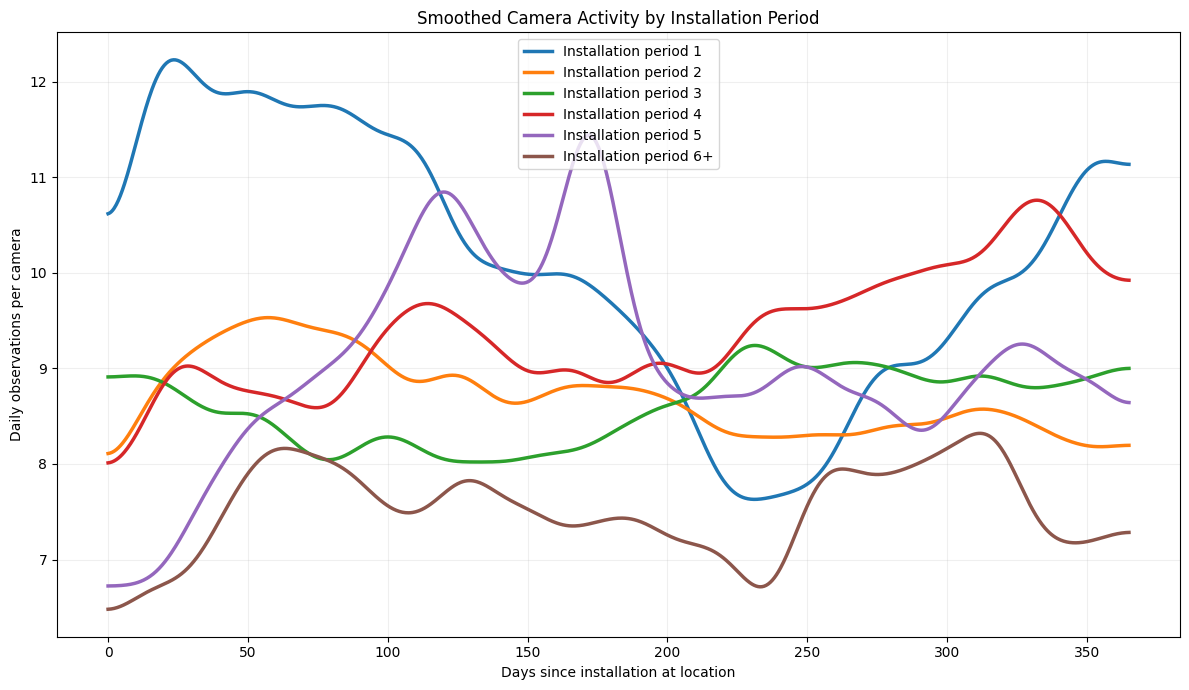

In [35]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline
from scipy.ndimage import gaussian_filter1d

# Merge periods 6 and above
df["period_group"] = df["period"].apply(
    lambda p: "6+" if p >= 6 else str(p)
)

# Count unique camera locations in each period group
camera_counts = (
    df.groupby("period_group")[["Latitude", "Longitude"]]
    .apply(lambda x: x.drop_duplicates().shape[0])
)

# Count daily observations by period
daily_counts = (
    df.dropna(subset=["issue_date", "period_group"])
    .groupby(["period_group", "issue_date"])
    .size()
    .rename("observations")
    .reset_index()
)

daily_counts["observations_per_camera"] = daily_counts.apply(
    lambda row: row["observations"] /
    camera_counts[row["period_group"]],
    axis=1
)

period_order = ["1", "2", "3", "4", "5", "6+"]

plt.figure(figsize=(12, 7))

for period in period_order:
    subset = daily_counts[
        daily_counts["period_group"] == period
    ].set_index("issue_date")["observations_per_camera"]

    if subset.empty:
        continue

    subset.index = subset.index.astype(int)
    days = np.arange(0, int(subset.index.max()) + 1)

    values = subset.reindex(days, fill_value=0).to_numpy()

    # Strong Gaussian smoothing for smooth, flowing curves
    smoothed = gaussian_filter1d(values, sigma=10)

    # Interpolate into a dense set of points for curvaceous lines
    smooth_days = np.linspace(days.min(), days.max(), 1000)
    smooth_values = make_interp_spline(
        days, smoothed, k=3
    )(smooth_days)

    # Avoid negative values from spline overshoot
    smooth_values = np.maximum(smooth_values, 0)

    plt.plot(
        smooth_days,
        smooth_values,
        linewidth=2.5,
        label=f"Installation period {period}"
    )

plt.xlabel("Days since installation at location")
plt.ylabel("Daily observations per camera")
plt.title("Smoothed Camera Activity by Installation Period")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [36]:
# --------------------------------------------------
# 5. Plot smoothed crash incidence normalized by area
#    Use crashes per camera vicinity per day
# --------------------------------------------------

# Count distinct camera locations
camera_counts = (
    period_starts.groupby("period")[
        ["Latitude", "Longitude"]
    ].apply(lambda x: x.drop_duplicates().shape[0])
)

# Assign each crash to a period group
assigned["period_group"] = assigned["period"].apply(
    lambda p: "6+" if p >= 6 else str(int(p))
)

period_order = ["1", "2", "3", "4", "5", "6+"]

plt.figure(figsize=(12, 7))

for period_group in period_order:
    subset = assigned.loc[
        assigned["period_group"] == period_group,
        ["relative_day", "period", "camera_lat", "camera_lon"]
    ].dropna(subset=["relative_day"])

    if subset.empty:
        continue

    # Number of unique camera locations represented in this group
    if period_group == "6+":
        relevant_periods = camera_counts[camera_counts.index >= 6].index
        n_cameras = period_starts[
            period_starts["period"].isin(relevant_periods)
        ][["Latitude", "Longitude"]].drop_duplicates().shape[0]
    else:
        n_cameras = period_starts[
            period_starts["period"] == int(period_group)
        ][["Latitude", "Longitude"]].drop_duplicates().shape[0]

    if n_cameras == 0:
        continue

    # Daily crash counts
    daily = (
        subset.assign(relative_day=subset["relative_day"].astype(int))
        .groupby("relative_day")
        .size()
    )

    days = np.arange(0, int(daily.index.max()) + 1)
    values = daily.reindex(days, fill_value=0).to_numpy(dtype=float)

    # Average crashes per camera location per day
    average_values = values / n_cameras

    # Smooth the curve
    smoothed = gaussian_filter1d(average_values, sigma=10)

    if len(days) >= 4:
        smooth_days = np.linspace(days.min(), days.max(), 1000)
        smooth_values = make_interp_spline(
            days, smoothed, k=3
        )(smooth_days)
        smooth_values = np.maximum(smooth_values, 0)
    else:
        smooth_days, smooth_values = days, smoothed

    plt.plot(
        smooth_days,
        smooth_values,
        linewidth=2.5,
        label=f"Installation period {period_group}"
    )

plt.xlabel("Days since camera installation at location")
plt.ylabel("Average nearby crashes per camera per day")
plt.title("Average Crash Incidence Near Red-Light Cameras by Installation Period")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

NameError: name 'period_starts' is not defined

Number of camera locations: 512

Camera-neighbor count summary:
count    512.000000
mean      12.371094
std        6.918521
min        0.000000
25%        7.000000
50%       12.000000
75%       16.000000
max       36.000000
Name: nearby_camera_count, dtype: float64

Spearman correlation: 0.317
P-value: 2.1419e-13
More nearby cameras are associated with more crashes.


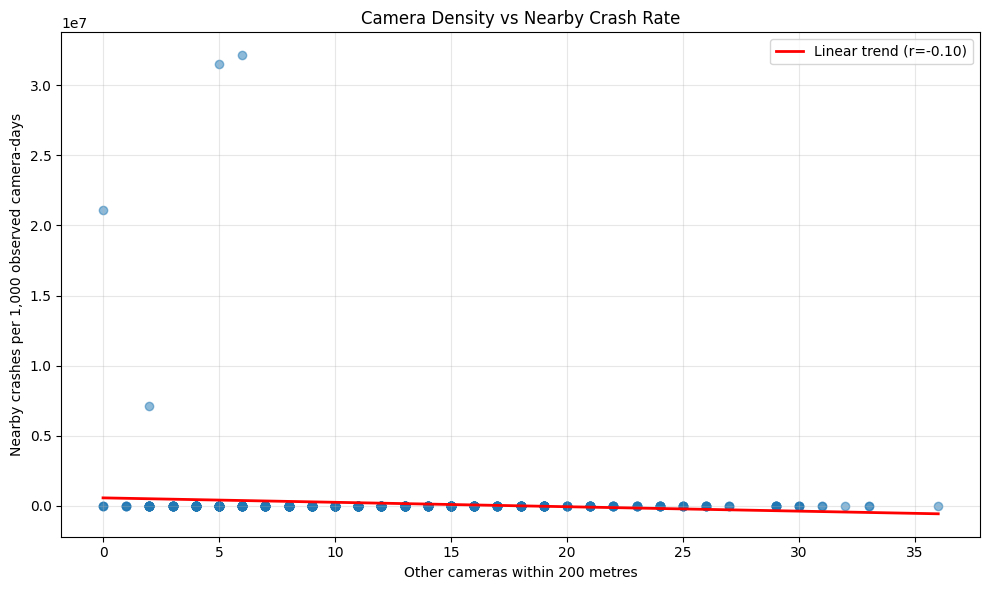


Crash rate by nearby camera density:
               camera_locations  avg_neighbor_cameras  avg_crash_rate  \
density_group                                                           
0                             4              0.000000    5.270000e+06   
1–2                          19              1.789474    3.747895e+05   
3–5                          73              4.205479    4.312740e+05   
6+                          416             14.406250    7.724038e+04   

               median_crash_rate  
density_group                     
0                   9.058441e-12  
1–2                 1.138159e-10  
3–5                 3.889928e-10  
6+                  1.458766e-09  


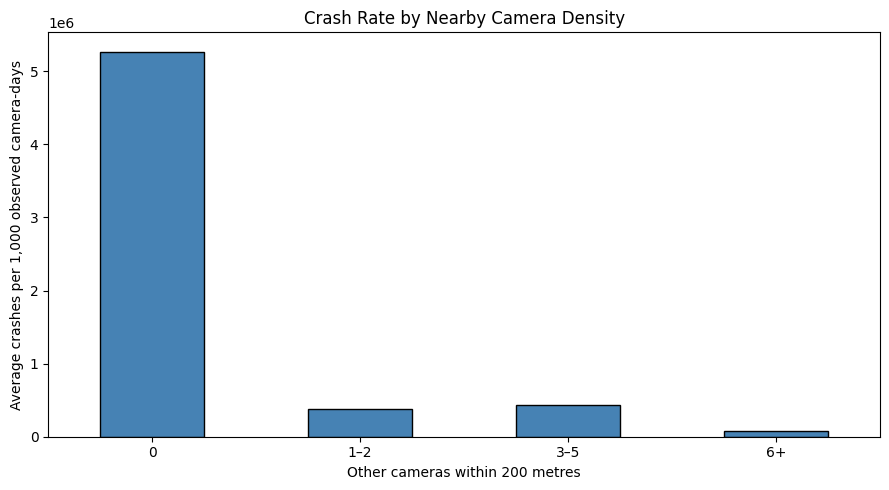

In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import BallTree
from scipy.stats import linregress, spearmanr
from scipy.ndimage import gaussian_filter1d

# --------------------------------------------------
# 1. Prepare camera locations
# --------------------------------------------------

EARTH_RADIUS_M = 6_371_000
RADIUS_M = 2100  # Approximate 30 city blocks

cameras = base_redlight_df.copy()

cameras["Latitude"] = pd.to_numeric(cameras["Latitude"], errors="coerce")
cameras["Longitude"] = pd.to_numeric(cameras["Longitude"], errors="coerce")

locations = (
    cameras[["Latitude", "Longitude"]]
    .dropna()
    .drop_duplicates()
    .reset_index(drop=True)
)

coords_rad = np.radians(locations[["Latitude", "Longitude"]].to_numpy())
tree = BallTree(coords_rad, metric="haversine")

# --------------------------------------------------
# 2. Count other cameras within 200 metres
# --------------------------------------------------

radius_rad = RADIUS_M / EARTH_RADIUS_M

neighbor_indices = tree.query_radius(coords_rad, r=radius_rad)

# Subtract one to exclude each camera itself
locations["nearby_camera_count"] = [
    len(indices) - 1 for indices in neighbor_indices
]

# --------------------------------------------------
# 3. Count crashes within 200 metres of each camera
# --------------------------------------------------

crashes = crash_df.copy()

crashes["LATITUDE"] = pd.to_numeric(crashes["LATITUDE"], errors="coerce")
crashes["LONGITUDE"] = pd.to_numeric(crashes["LONGITUDE"], errors="coerce")
crashes["CRASH DATE"] = pd.to_datetime(
    crashes["CRASH DATE"], errors="coerce"
)

crashes = crashes.dropna(subset=["LATITUDE", "LONGITUDE", "CRASH DATE"])

crash_coords = np.radians(
    crashes[["LATITUDE", "LONGITUDE"]].to_numpy()
)

crash_tree = BallTree(coords_rad, metric="haversine")
crash_neighbors = crash_tree.query_radius(crash_coords, r=radius_rad)

# Count each crash for every camera within 200 metres
crash_counts = np.zeros(len(locations), dtype=int)

for camera_ids in crash_neighbors:
    crash_counts[camera_ids] += 1

locations["nearby_crash_count"] = crash_counts

# --------------------------------------------------
# 4. Calculate crash rate per camera per observed day
# --------------------------------------------------
# This helps account for cameras that have been observed
# for different lengths of time, using available camera dates.
#
# If issue_date is a numeric day offset, its range approximates
# the observation duration for each location.

if "issue_date_absolute" in cameras.columns:
    cameras["absolute_day"] = pd.to_numeric(
        cameras["issue_date_absolute"], errors="coerce"
    )
else:
    cameras["absolute_day"] = pd.to_numeric(
        cameras["issue_date"], errors="coerce"
    )

duration = (
    cameras.dropna(subset=["absolute_day"])
    .groupby(["Latitude", "Longitude"])["absolute_day"]
    .agg(first_day="min", last_day="max")
    .reset_index()
)

duration["observed_days"] = (
    duration["last_day"] - duration["first_day"] + 1
).clip(lower=1)

locations = locations.merge(
    duration[["Latitude", "Longitude", "observed_days"]],
    on=["Latitude", "Longitude"],
    how="left"
)

# Approximate crash rate per camera per 1,000 observed days
locations["crashes_per_1000_days"] = (
    locations["nearby_crash_count"]
    / locations["observed_days"]
    * 1000
)

# --------------------------------------------------
# 5. Correlation: camera density vs crash rate
# --------------------------------------------------

valid = locations.dropna(
    subset=["nearby_camera_count", "crashes_per_1000_days"]
).copy()

print("Number of camera locations:", len(valid))
print("\nCamera-neighbor count summary:")
print(valid["nearby_camera_count"].describe())

if len(valid) >= 3 and valid["nearby_camera_count"].nunique() > 1:
    rho, p_value = spearmanr(
        valid["nearby_camera_count"],
        valid["crashes_per_1000_days"]
    )

    print(f"\nSpearman correlation: {rho:.3f}")
    print(f"P-value: {p_value:.5g}")

    if rho < 0:
        print("More nearby cameras are associated with fewer crashes.")
    elif rho > 0:
        print("More nearby cameras are associated with more crashes.")
    else:
        print("No monotonic association detected.")
else:
    print("Not enough variation or data to calculate correlation.")

# --------------------------------------------------
# 6. Scatterplot with trend line
# --------------------------------------------------

plt.figure(figsize=(10, 6))

plt.scatter(
    valid["nearby_camera_count"],
    valid["crashes_per_1000_days"],
    alpha=0.5
)

x = valid["nearby_camera_count"]
y = valid["crashes_per_1000_days"]

if len(valid) >= 2 and x.nunique() > 1:
    slope, intercept, r_value, p_value, _ = linregress(x, y)

    line_x = np.linspace(x.min(), x.max(), 200)

    plt.plot(
        line_x,
        intercept + slope * line_x,
        color="red",
        linewidth=2,
        label=f"Linear trend (r={r_value:.2f})"
    )
    plt.legend()

plt.xlabel("Other cameras within 200 metres")
plt.ylabel("Nearby crashes per 1,000 observed camera-days")
plt.title("Camera Density vs Nearby Crash Rate")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 7. Compare crash rates by camera density
# --------------------------------------------------

# Group cameras by the number of neighboring cameras
valid["density_group"] = pd.cut(
    valid["nearby_camera_count"],
    bins=[-1, 0, 2, 5, np.inf],
    labels=["0", "1–2", "3–5", "6+"]
)

summary = valid.groupby(
    "density_group", observed=False
).agg(
    camera_locations=("nearby_crash_count", "size"),
    avg_neighbor_cameras=("nearby_camera_count", "mean"),
    avg_crash_rate=("crashes_per_1000_days", "mean"),
    median_crash_rate=("crashes_per_1000_days", "median")
)

print("\nCrash rate by nearby camera density:")
print(summary)

summary["avg_crash_rate"].plot(
    kind="bar",
    figsize=(9, 5),
    color="steelblue",
    edgecolor="black"
)

plt.xlabel("Other cameras within 200 metres")
plt.ylabel("Average crashes per 1,000 observed camera-days")
plt.title("Crash Rate by Nearby Camera Density")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()